# Week 9 - Gradient Boosting
## Dataset: NOAA Storm Events

This week covers gradient boosting, along with the settings that control it, which are the learning rate, the number of estimators (trees), the tree depth, and regularization. Like a random forest, gradient boosting combines many decision trees, but it builds them in a different way. A random forest grows its trees independently and averages them. Gradient boosting grows them one after another, and each new tree is fit to the mistakes the model is still making, specifically to the gradient of the loss with respect to the current predictions. The final prediction is the starting guess plus the sum of every tree's contribution, with each contribution scaled down by the learning rate.

The question is the same one Weeks 4 to 6 asked of Storm Events, whether a 2017 event reported any property damage, with the same features and the same split that keeps whole storm episodes out of training. That makes this notebook a direct comparison with logistic regression (Week 4), the SVM (Week 5), and the random forest (Week 6), and it is meant as groundwork for Milestone Two. It also tests a new version of the lesson from those weeks. Early stopping needs a validation set, and if that set is drawn at random, events from the same storm end up on both sides of it.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, GroupShuffleSplit, GroupKFold, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (GradientBoostingClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             log_loss, RocCurveDisplay)

warnings.filterwarnings('ignore', category=FutureWarning)

df = pd.read_csv('StormEvents_details-ftp_v1.0_d2017_c20260519.csv', low_memory=False)


def parse_damage(val):
    if pd.isna(val):
        return np.nan
    val = str(val).strip().upper()
    mult = {'K': 1e3, 'M': 1e6, 'B': 1e9}
    try:
        return float(val[:-1]) * mult[val[-1]] if val[-1] in mult else float(val)
    except ValueError:
        return np.nan


df['damageProperty'] = df['DAMAGE_PROPERTY'].apply(parse_damage)
print('All 2017 events:', len(df))

All 2017 events: 57041


### Data, features, and splits

The features are the starting latitude and longitude, the month, the log of event duration, and indicators for the eight most common event types, exactly as in Weeks 4 to 6. Like other tree models, gradient boosting needs no feature scaling. The test set is 7,961 events from storm episodes that never appear in training. Inside the training set, 20% of the episodes are set aside as a validation set, so the model can be watched as it grows without touching the test set. Logistic regression and a random forest with the Week 6 settings are refit as reference points.

In [2]:
data = df.dropna(subset=['damageProperty', 'BEGIN_LAT', 'BEGIN_LON']).copy()
data['damaged'] = (data['damageProperty'] > 0).astype(int)
begin = pd.to_datetime(data['BEGIN_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
end = pd.to_datetime(data['END_DATE_TIME'], format='%d-%b-%y %H:%M:%S', errors='coerce')
data['logDuration'] = np.log10(((end - begin).dt.total_seconds() / 3600).clip(lower=0) + 0.1)
data['month'] = begin.dt.month
type_cols = []
for t in data['EVENT_TYPE'].value_counts().head(8).index:
    col = 'type_' + t.replace(' ', '')
    data[col] = (data['EVENT_TYPE'] == t).astype(int)
    type_cols.append(col)
data = data.dropna(subset=['month', 'logDuration']).reset_index(drop=True)
numeric = ['BEGIN_LAT', 'BEGIN_LON', 'month', 'logDuration']
features = numeric + type_cols
X = data[features]
y = data['damaged'].values
groups = data['EPISODE_ID'].values

# Same episode-grouped split as Weeks 4 to 6
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y[train_idx], y[test_idx]
g_train = groups[train_idx]

# A validation set of whole episodes carved out of the training events
fit_pos, val_pos = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=1).split(X_train, y_train, g_train))
X_fit, X_val, y_fit, y_val = X_train.iloc[fit_pos], X_train.iloc[val_pos], y_train[fit_pos], y_train[val_pos]
print('Events used:', len(data), '| share with damage reported:', round(y.mean(), 3))
print('Training events:', len(train_idx), f'(fit {len(fit_pos)}, validation {len(val_pos)})', '| test events:', len(test_idx))
print('Episodes shared between fit and validation:', len(set(g_train[fit_pos]) & set(g_train[val_pos])),
      '| between training and test:', len(set(g_train) & set(groups[test_idx])))

prep = ColumnTransformer([('num', StandardScaler(), numeric), ('types', 'passthrough', type_cols)])
logit = Pipeline([('prep', prep), ('lr', LogisticRegression(max_iter=3000))]).fit(X_train, y_train)
forest = RandomForestClassifier(n_estimators=400, max_features=6, min_samples_leaf=3, n_jobs=-1,
                                random_state=0).fit(X_train, y_train)
p_logit = logit.predict_proba(X_test)[:, 1]
p_forest = forest.predict_proba(X_test)[:, 1]
print(f'Reference test ROC-AUC, logistic regression: {roc_auc_score(y_test, p_logit):.4f}')
print(f'Reference test ROC-AUC, Week 6 random forest settings: {roc_auc_score(y_test, p_forest):.4f}')

Events used: 31863 | share with damage reported: 0.347
Training events: 23902 (fit 19402, validation 4500) | test events: 7961
Episodes shared between fit and validation: 0 | between training and test: 0


Reference test ROC-AUC, logistic regression: 0.8212
Reference test ROC-AUC, Week 6 random forest settings: 0.9165


### How boosting builds a model

The first model uses scikit-learn's `GradientBoostingClassifier` with its defaults, 100 trees of depth 3 and a learning rate of 0.1. The plot tracks the log loss on the training events and the validation episodes after each tree is added.

Default gradient boosting (100 trees, learning rate 0.1, depth 3), validation ROC-AUC: 0.8740
Log loss before any tree (predicting the base rate): 0.6559
Validation log loss after 1, 10, and 100 trees: 0.6282, 0.5150, 0.4246


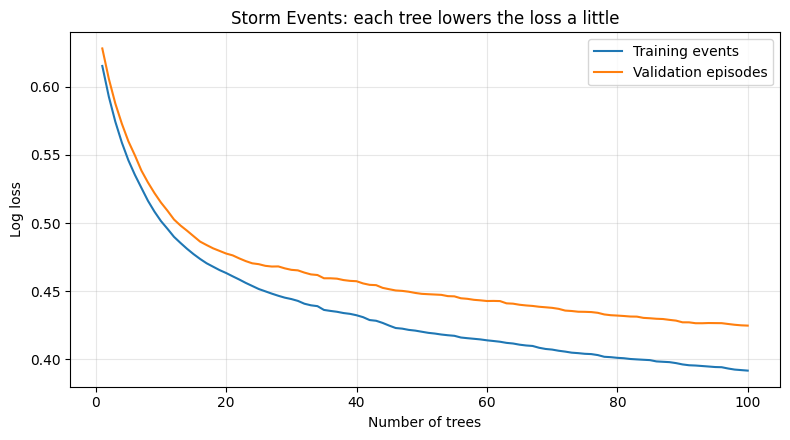

In [3]:
gb = GradientBoostingClassifier(random_state=0).fit(X_fit, y_fit)
stages = np.arange(1, gb.n_estimators_ + 1)
train_loss = [log_loss(y_fit, p[:, 1]) for p in gb.staged_predict_proba(X_fit)]
val_loss = [log_loss(y_val, p[:, 1]) for p in gb.staged_predict_proba(X_val)]
print(f'Default gradient boosting (100 trees, learning rate 0.1, depth 3), validation ROC-AUC: '
      f'{roc_auc_score(y_val, gb.predict_proba(X_val)[:, 1]):.4f}')
print(f'Log loss before any tree (predicting the base rate): {log_loss(y_val, np.full(len(y_val), y_fit.mean())):.4f}')
print(f'Validation log loss after 1, 10, and 100 trees: {val_loss[0]:.4f}, {val_loss[9]:.4f}, {val_loss[-1]:.4f}')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(stages, train_loss, label='Training events')
ax.plot(stages, val_loss, label='Validation episodes')
ax.set_xlabel('Number of trees')
ax.set_ylabel('Log loss')
ax.set_title('Storm Events: each tree lowers the loss a little')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Before any tree is fit, the model predicts the base rate for every event, which gives a validation log loss of 0.656. The first tree brings it to 0.628, ten trees to 0.515, and 100 trees to 0.425, for a validation ROC-AUC of 0.874. Each tree only nudges the predictions, which is the point of a learning rate below 1. The training loss keeps falling a little faster than the validation loss, so even this small model is starting to fit the training events better than new storms.

### Learning rate and the number of trees

The learning rate and the number of trees work as a pair. A smaller learning rate shrinks each tree's contribution, so the model needs more trees to reach the same fit, but it takes smaller and more careful steps. The next cell fits depth-3 models with learning rates of 1.0, 0.3, 0.1, and 0.03 and records the validation log loss after every tree, so the best number of trees for each rate can be read off the curve.

Took 102 seconds
 Learning rate  Trees fit  Best number of trees  Best validation log loss  Validation ROC-AUC at best  Validation log loss at the last tree
          1.00        300                    51                    0.4005                      0.8943                                0.5148
          0.30        800                   384                    0.3646                      0.9066                                0.3802
          0.10       2000                  1273                    0.3617                      0.9080                                0.3644
          0.03       2000                  2000                    0.3710                      0.9029                                0.3710


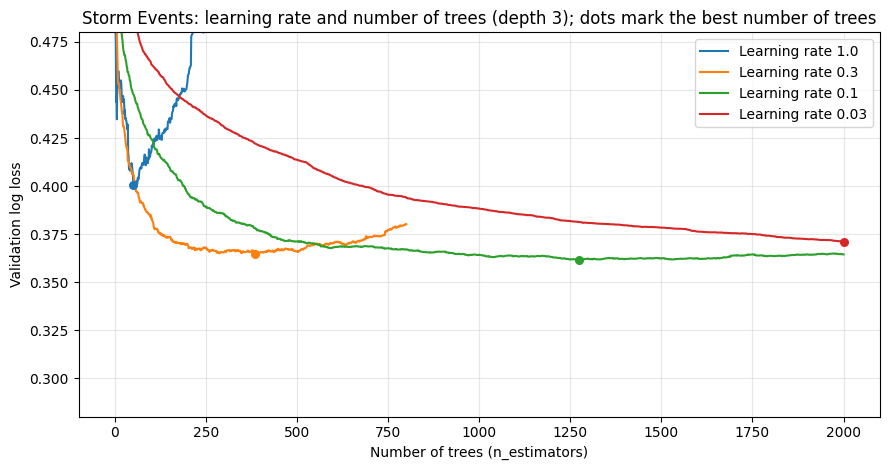

In [4]:
settings = [(1.0, 300), (0.3, 800), (0.1, 2000), (0.03, 2000)]
curves, rows = {}, []
t0 = time.time()
for lr, n in settings:
    m = GradientBoostingClassifier(learning_rate=lr, n_estimators=n, max_depth=3, random_state=0).fit(X_fit, y_fit)
    probs = list(m.staged_predict_proba(X_val))
    losses = np.array([log_loss(y_val, p[:, 1]) for p in probs])
    best = int(np.argmin(losses))
    curves[lr] = losses
    rows.append({'Learning rate': lr, 'Trees fit': n, 'Best number of trees': best + 1,
                 'Best validation log loss': losses[best],
                 'Validation ROC-AUC at best': roc_auc_score(y_val, probs[best][:, 1]),
                 'Validation log loss at the last tree': losses[-1]})
lr_table = pd.DataFrame(rows)
print(f'Took {time.time() - t0:.0f} seconds')
print(lr_table.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.8))
for lr, losses in curves.items():
    line, = ax.plot(np.arange(1, len(losses) + 1), losses, label=f'Learning rate {lr}')
    b = int(np.argmin(losses))
    ax.scatter([b + 1], [losses[b]], color=line.get_color(), zorder=3, s=30)
ax.set_xlabel('Number of trees (n_estimators)')
ax.set_ylabel('Validation log loss')
ax.set_ylim(0.28, 0.48)
ax.set_title('Storm Events: learning rate and number of trees (depth 3); dots mark the best number of trees')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The plot shows the trade-off clearly. With a learning rate of 1.0 the validation loss bottoms out after only 51 trees (0.401) and then climbs steeply, reaching 0.515 by tree 300, because each tree is allowed to correct the previous ones in full and the model quickly starts fitting noise. A learning rate of 0.3 reaches a better minimum (0.365) at 384 trees and then drifts upward. A learning rate of 0.1 does best (0.362 at 1,273 trees, validation ROC-AUC 0.908) and stays nearly flat afterward, so it is much less sensitive to the exact number of trees. At 0.03 the loss is still falling after 2,000 trees (0.371), so that rate would need even more trees to catch up. Smaller steps reach a better and more stable minimum, at the cost of more trees and more time.

### Tree depth

The depth of each tree sets how many features can interact inside one tree. A depth-1 tree (a stump) splits on a single feature, so a boosted model of stumps is additive, a sum of separate effects for each feature with no interactions. Deeper trees can capture combinations, such as thunderstorm wind in a particular region. The next cell uses `HistGradientBoostingClassifier`, scikit-learn's faster histogram-based version of the same algorithm, with a learning rate of 0.1 and early stopping on the validation episodes, which stops adding trees once the validation loss has not improved for 50 trees.

 max_depth  Trees kept by early stopping  Train ROC-AUC  Validation ROC-AUC  Validation log loss    Gap
         1                          1540         0.8643              0.8546               0.4571 0.0098
         2                          2336         0.9304              0.9034               0.3713 0.0269
         3                           768         0.9455              0.9114               0.3554 0.0340
         5                           300         0.9634              0.9197               0.3397 0.0437
         8                           165         0.9805              0.9211               0.3398 0.0593
        12                           100         0.9882              0.9202               0.3538 0.0679


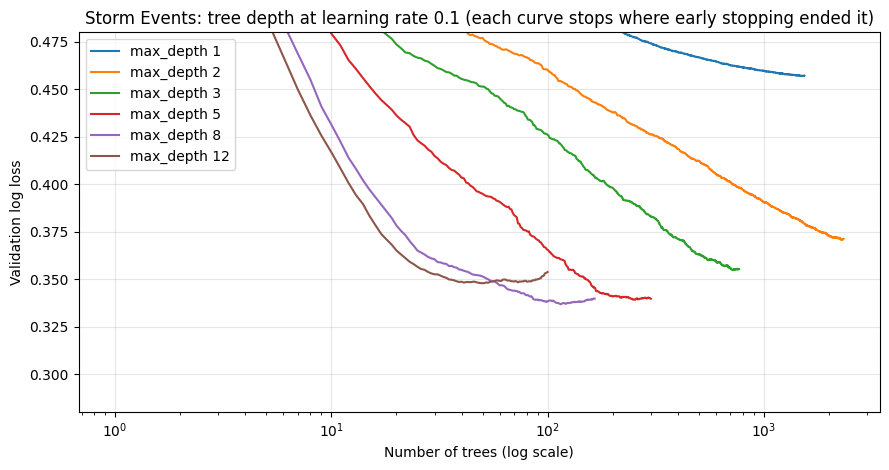

In [5]:
depth_rows, depth_curves = [], {}
for depth in [1, 2, 3, 5, 8, 12]:
    m = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=3000, max_depth=depth, max_leaf_nodes=None,
                                       early_stopping=True, validation_fraction=None, n_iter_no_change=50,
                                       scoring='loss', random_state=0)
    m.fit(X_fit, y_fit, X_val=X_val, y_val=y_val)
    p_tr, p_va = m.predict_proba(X_fit)[:, 1], m.predict_proba(X_val)[:, 1]
    depth_curves[depth] = -m.validation_score_
    depth_rows.append({'max_depth': depth, 'Trees kept by early stopping': m.n_iter_,
                       'Train ROC-AUC': roc_auc_score(y_fit, p_tr), 'Validation ROC-AUC': roc_auc_score(y_val, p_va),
                       'Validation log loss': log_loss(y_val, p_va)})
depth_table = pd.DataFrame(depth_rows)
depth_table['Gap'] = depth_table['Train ROC-AUC'] - depth_table['Validation ROC-AUC']
print(depth_table.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.8))
for depth, losses in depth_curves.items():
    ax.plot(np.arange(len(losses)), losses, label=f'max_depth {depth}')
ax.set_xscale('log')
ax.set_ylim(0.28, 0.48)
ax.set_xlabel('Number of trees (log scale)')
ax.set_ylabel('Validation log loss')
ax.set_title('Storm Events: tree depth at learning rate 0.1 (each curve stops where early stopping ended it)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Depth matters a great deal for this question. Stumps reach only 0.855 validation ROC-AUC even with 1,540 trees, depth 3 reaches 0.911, and depths 5 and 8 reach about 0.920 to 0.921 with far fewer trees (300 and 165). Going to depth 12 adds nothing. Its validation loss is worse than depth 8 (0.354 against 0.340), and its curve turns back up before early stopping ends it. The gap between training and validation ROC-AUC grows steadily with depth, from 0.010 for stumps to 0.068 at depth 12, which is the usual sign that deeper trees are starting to memorize. The large gain from stumps to depth 5 says that damage reports depend on combinations of features, mainly event type together with location, which an additive model cannot represent.

### Early stopping and regularization

Early stopping is itself a form of regularization, since it limits the number of trees. It only works if the validation set it watches is honest. The next cell trains the same model twice, once stopping on a random 20% of the training events and once stopping on 20% of the training episodes, and compares each validation score with the score on the test episodes. The cell after that tests the other regularization settings one at a time, which are an L2 penalty on the leaf values (`l2_regularization`), the minimum number of events in a leaf (`min_samples_leaf`), the share of features each split may consider (`max_features`), and stochastic boosting, where each tree is fit to a random half of the training events (`subsample`).

In [6]:
# Early stopping needs a validation set. Compare a random one with one made of whole episodes.
r_fit, r_val = train_test_split(np.arange(len(y_train)), test_size=0.2, stratify=y_train, random_state=1)
rows = []
for name, (fi, va) in [('Random validation events', (r_fit, r_val)), ('Validation episodes (grouped)', (fit_pos, val_pos))]:
    m = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=3000, early_stopping=True, validation_fraction=None,
                                       n_iter_no_change=50, scoring='loss', random_state=0)
    m.fit(X_train.iloc[fi], y_train[fi], X_val=X_train.iloc[va], y_val=y_train[va])
    rows.append({'Validation set for early stopping': name, 'Trees kept': m.n_iter_,
                 'Validation ROC-AUC (the estimate)': roc_auc_score(y_train[va], m.predict_proba(X_train.iloc[va])[:, 1]),
                 'Test ROC-AUC (unseen episodes)': roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])})
es = pd.DataFrame(rows)
es['Overstatement'] = es['Validation ROC-AUC (the estimate)'] - es['Test ROC-AUC (unseen episodes)']
print(es.round(4).to_string(index=False))

Validation set for early stopping  Trees kept  Validation ROC-AUC (the estimate)  Test ROC-AUC (unseen episodes)  Overstatement
         Random validation events         516                             0.9482                          0.9183         0.0299
    Validation episodes (grouped)         257                             0.9250                          0.9175         0.0075


Each row changes one setting from the default (learning rate 0.1, 31 leaves, min_samples_leaf 20, no L2 penalty)
                           Regularizer  Setting  Trees kept  Train ROC-AUC  Validation ROC-AUC    Gap
                     l2_regularization      0.0         257         0.9756              0.9250 0.0506
                     l2_regularization      1.0         311         0.9755              0.9246 0.0508
                     l2_regularization     10.0         423         0.9715              0.9236 0.0479
                     l2_regularization    100.0         696         0.9633              0.9206 0.0427
                      min_samples_leaf      1.0         312         0.9834              0.9219 0.0615
                      min_samples_leaf     20.0         257         0.9756              0.9250 0.0506
                      min_samples_leaf    100.0         248         0.9684              0.9222 0.0462
                      min_samples_leaf    500.0         486         0.9

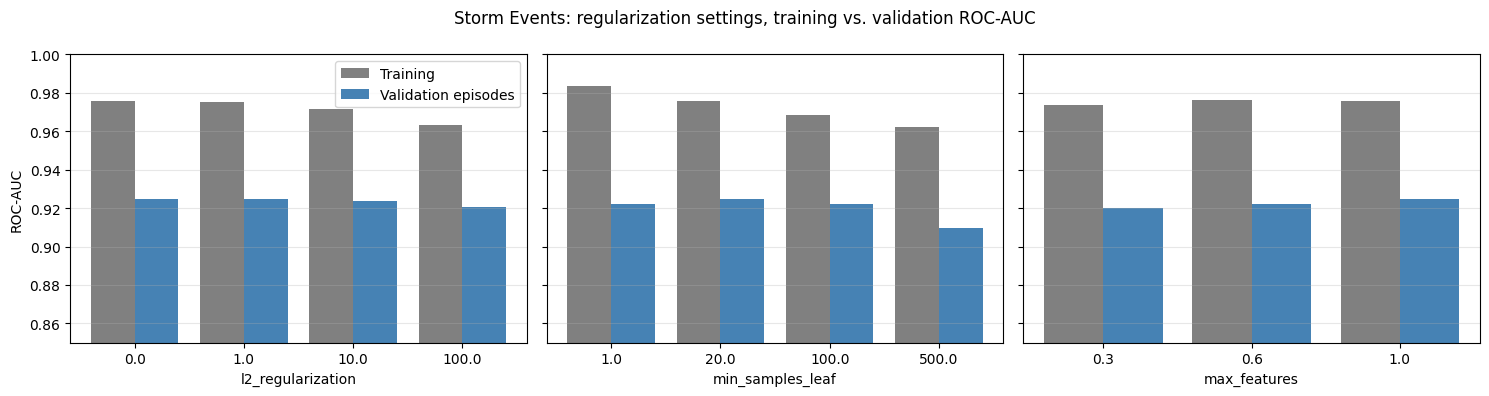

In [7]:
def hgb_check(label, setting, **params):
    base = dict(learning_rate=0.1, max_iter=3000, early_stopping=True, validation_fraction=None,
                n_iter_no_change=50, scoring='loss', random_state=0)
    base.update(params)
    m = HistGradientBoostingClassifier(**base).fit(X_fit, y_fit, X_val=X_val, y_val=y_val)
    p_tr, p_va = m.predict_proba(X_fit)[:, 1], m.predict_proba(X_val)[:, 1]
    return {'Regularizer': label, 'Setting': setting, 'Trees kept': m.n_iter_,
            'Train ROC-AUC': roc_auc_score(y_fit, p_tr), 'Validation ROC-AUC': roc_auc_score(y_val, p_va)}


reg_rows = []
for l2 in [0, 1, 10, 100]:
    reg_rows.append(hgb_check('l2_regularization', l2, l2_regularization=l2))
for leaf in [1, 20, 100, 500]:
    reg_rows.append(hgb_check('min_samples_leaf', leaf, min_samples_leaf=leaf))
for frac in [0.3, 0.6, 1.0]:
    reg_rows.append(hgb_check('max_features', frac, max_features=frac))
for sub in [1.0, 0.5]:
    m = GradientBoostingClassifier(learning_rate=0.1, n_estimators=800, max_depth=3, subsample=sub,
                                   random_state=0).fit(X_fit, y_fit)
    losses = [log_loss(y_val, p[:, 1]) for p in m.staged_predict_proba(X_val)]
    best = int(np.argmin(losses)) + 1
    m_best = GradientBoostingClassifier(learning_rate=0.1, n_estimators=best, max_depth=3, subsample=sub,
                                        random_state=0).fit(X_fit, y_fit)
    reg_rows.append({'Regularizer': 'subsample (GradientBoostingClassifier)', 'Setting': sub, 'Trees kept': best,
                     'Train ROC-AUC': roc_auc_score(y_fit, m_best.predict_proba(X_fit)[:, 1]),
                     'Validation ROC-AUC': roc_auc_score(y_val, m_best.predict_proba(X_val)[:, 1])})
reg = pd.DataFrame(reg_rows)
reg['Gap'] = reg['Train ROC-AUC'] - reg['Validation ROC-AUC']
print('Each row changes one setting from the default (learning rate 0.1, 31 leaves, min_samples_leaf 20, no L2 penalty)')
print(reg.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, name in zip(axes, ['l2_regularization', 'min_samples_leaf', 'max_features']):
    part = reg[reg['Regularizer'] == name]
    x = np.arange(len(part))
    ax.bar(x - 0.2, part['Train ROC-AUC'], width=0.4, color='gray', label='Training')
    ax.bar(x + 0.2, part['Validation ROC-AUC'], width=0.4, color='steelblue', label='Validation episodes')
    ax.set_xticks(x)
    ax.set_xticklabels(part['Setting'].astype(str))
    ax.set_xlabel(name)
    ax.set_ylim(0.85, 1.0)
    ax.grid(alpha=0.3, axis='y')
axes[0].set_ylabel('ROC-AUC')
axes[0].legend()
fig.suptitle('Storm Events: regularization settings, training vs. validation ROC-AUC')
plt.tight_layout()
plt.show()

The early stopping comparison repeats the lesson from Weeks 5 and 6 in a new place. With random validation events, early stopping kept 516 trees and reported a validation ROC-AUC of 0.948, while the test episodes gave 0.918, an overstatement of 0.030. With validation episodes it kept 257 trees, estimated 0.925, and the test gave 0.918, an overstatement of only 0.008. The random validation set contains siblings of the training events, so it keeps rewarding trees that memorize storms and lets the model grow twice as large. The final test score barely changed here, but the validation number would have been badly misleading.

The other regularization settings matter much less than depth and the learning rate. An L2 penalty of 100 lowers the training ROC-AUC and needs more trees, but it also lowers validation ROC-AUC slightly (0.921 against 0.925), so the default of no penalty is fine. Leaves of a single event overfit (gap 0.062), leaves of 500 events underfit (validation 0.910), and the default of 20 is best. Considering only some features at each split did not help, since there are only 12 features. Stochastic boosting with `subsample = 0.5` gave a small gain over using every event (0.907 against 0.905) with a slightly smaller gap.

### Tuning everything together

The settings interact, so the last step searches them together with `RandomizedSearchCV`, trying 40 random combinations of learning rate, number of trees, tree size, leaf size, L2 penalty, and feature share, each scored by 5-fold cross-validation grouped by episode. Early stopping is turned off for the search, because its internal validation set would be drawn at random and would leak episodes, as the cell above showed. The number of trees is searched directly instead.

In [8]:
# Early stopping is turned off here, because its internal validation set would be random events,
# not whole episodes. The number of trees is searched directly instead.
param_dist = {'learning_rate': [0.03, 0.05, 0.1, 0.2],
              'max_iter': [100, 200, 400, 800],
              'max_leaf_nodes': [15, 31, 63],
              'max_depth': [None, 6, 10],
              'min_samples_leaf': [5, 20, 50, 100],
              'l2_regularization': [0, 0.1, 1, 10],
              'max_features': [0.5, 0.75, 1.0]}
grouped_cv = list(GroupKFold(n_splits=5).split(X_train, y_train, g_train))
search = RandomizedSearchCV(HistGradientBoostingClassifier(early_stopping=False, random_state=0), param_dist,
                            n_iter=40, scoring='roc_auc', n_jobs=4, random_state=0, cv=grouped_cv,
                            return_train_score=True)
t0 = time.time()
search.fit(X_train, y_train)
print(f'Randomized search of 40 settings x 5 grouped folds took {time.time() - t0:.0f} seconds')
res = pd.DataFrame(search.cv_results_)
cols = ['param_learning_rate', 'param_max_iter', 'param_max_leaf_nodes', 'param_max_depth', 'param_min_samples_leaf',
        'param_l2_regularization', 'param_max_features', 'mean_train_score', 'mean_test_score']
print(res.sort_values('mean_test_score', ascending=False)[cols].head(6).round(4).to_string(index=False))
print()
print('Best settings:', search.best_params_)
print(f'Best grouped CV ROC-AUC: {search.best_score_:.4f}')
print(f'Spread of CV ROC-AUC across all 40 settings: {res["mean_test_score"].min():.4f} to {res["mean_test_score"].max():.4f}')

Randomized search of 40 settings x 5 grouped folds took 326 seconds
 param_learning_rate  param_max_iter  param_max_leaf_nodes param_max_depth  param_min_samples_leaf  param_l2_regularization  param_max_features  mean_train_score  mean_test_score
                0.03             800                    63            None                     100                      0.1                1.00            0.9819           0.9186
                0.20             100                    63            None                     100                      1.0                1.00            0.9781           0.9182
                0.05             400                    31              10                      20                      0.0                0.75            0.9694           0.9173
                0.20             200                    63              10                      20                      0.0                0.75            0.9931           0.9158
                0.20             400 

### Final evaluation on held-out storm episodes

Test events (unseen episodes): 7961
                                          Model  Accuracy  Balanced acc.     F1  Log loss  ROC-AUC
                                 Majority class    0.6514         0.5000 0.0000    0.6466   0.5000
                            Logistic regression    0.7715         0.7438 0.6656    0.4982   0.8212
                Random forest (Week 6 settings)    0.8501         0.8208 0.7711    0.3474   0.9165
            Gradient boosting, default settings    0.7996         0.7604 0.6871    0.4364   0.8649
Gradient boosting, tuned (HistGradientBoosting)    0.8569         0.8318 0.7849    0.3450   0.9204



Tuned model, training ROC-AUC 0.9791 vs. test ROC-AUC 0.9204



                          Model  Random split AUC  Episode split AUC    Gap
Random forest (Week 6 settings)            0.9449             0.9165 0.0285
       Gradient boosting, tuned            0.9453             0.9204 0.0249


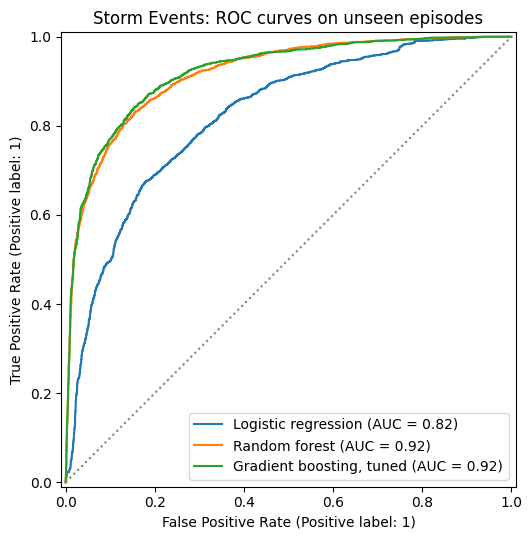

In [9]:
def scores(name, prob):
    pred = (prob >= 0.5).astype(int)
    return {'Model': name, 'Accuracy': accuracy_score(y_test, pred), 'Balanced acc.': balanced_accuracy_score(y_test, pred),
            'F1': f1_score(y_test, pred), 'Log loss': log_loss(y_test, prob), 'ROC-AUC': roc_auc_score(y_test, prob)}


best = search.best_estimator_
default_gb = GradientBoostingClassifier(random_state=0).fit(X_train, y_train)
p_default = default_gb.predict_proba(X_test)[:, 1]
p_best = best.predict_proba(X_test)[:, 1]
results = pd.DataFrame([
    scores('Majority class', np.full(len(y_test), y_train.mean())),
    scores('Logistic regression', p_logit),
    scores('Random forest (Week 6 settings)', p_forest),
    scores('Gradient boosting, default settings', p_default),
    scores('Gradient boosting, tuned (HistGradientBoosting)', p_best),
])
print('Test events (unseen episodes):', len(y_test))
print(results.round(4).to_string(index=False))
print()
print(f'Tuned model, training ROC-AUC {roc_auc_score(y_train, best.predict_proba(X_train)[:, 1]):.4f} '
      f'vs. test ROC-AUC {roc_auc_score(y_test, p_best):.4f}')

# The same models scored with an ordinary random split, ignoring storm episodes
r_train, r_test = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=0)
rows = []
for name, model, p_ep in [('Random forest (Week 6 settings)', RandomForestClassifier(n_estimators=400, max_features=6, min_samples_leaf=3,
                                                                                     n_jobs=-1, random_state=0), p_forest),
                          ('Gradient boosting, tuned', HistGradientBoostingClassifier(**best.get_params()), p_best)]:
    model.fit(X.iloc[r_train], y[r_train])
    rows.append({'Model': name, 'Random split AUC': roc_auc_score(y[r_test], model.predict_proba(X.iloc[r_test])[:, 1]),
                 'Episode split AUC': roc_auc_score(y_test, p_ep)})
gap = pd.DataFrame(rows)
gap['Gap'] = gap['Random split AUC'] - gap['Episode split AUC']
print()
print(gap.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, prob in [('Logistic regression', p_logit), ('Random forest', p_forest), ('Gradient boosting, tuned', p_best)]:
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=ax)
ax.plot([0, 1], [0, 1], color='gray', linestyle=':')
ax.set_title('Storm Events: ROC curves on unseen episodes')
plt.tight_layout()
plt.show()

Permutation importance (drop in test ROC-AUC when the feature is shuffled):
BEGIN_LON                      0.1669
type_ThunderstormWind          0.1555
BEGIN_LAT                      0.1077
logDuration                    0.0572
type_MarineThunderstormWind    0.0241
type_Tornado                   0.0174
type_Lightning                 0.0102
month                          0.0056
type_HeavyRain                 0.0053
type_FlashFlood                0.0042
type_Hail                      0.0030
type_Flood                     0.0010


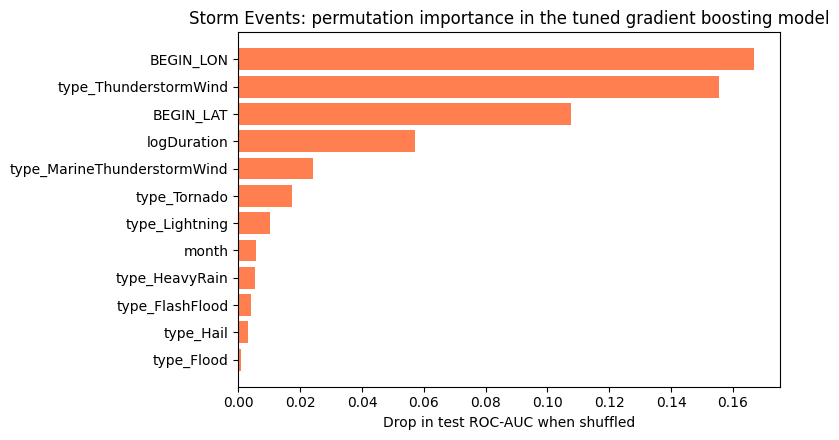

In [10]:
perm = permutation_importance(best, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=0, n_jobs=4)
imp = pd.Series(perm.importances_mean, index=features).sort_values()
print('Permutation importance (drop in test ROC-AUC when the feature is shuffled):')
print(imp.iloc[::-1].round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp.index, imp.values, color='coral')
ax.set_xlabel('Drop in test ROC-AUC when shuffled')
ax.set_title('Storm Events: permutation importance in the tuned gradient boosting model')
plt.tight_layout()
plt.show()

## Discussion

### Overfitting

Gradient boosting overfits in a different way from a random forest. A forest only gets more stable as trees are added, but a boosted model keeps fitting the training data more closely with every tree, so it eventually starts fitting noise. The learning rate curves show this directly, with the validation loss at a learning rate of 1.0 rising from 0.401 at 51 trees to 0.515 at 300. Four things kept it under control here. A small learning rate made each tree's contribution small, early stopping or a searched number of trees limited how many trees were added, moderate tree depth and a minimum leaf size limited how much each tree could memorize, and every one of these settings was chosen on whole storm episodes the model had not seen.

The tuned model's training ROC-AUC is 0.979 and its test ROC-AUC is 0.920, a gap of 0.059, similar to the gaps of the best depths in the validation experiments. Its random split score (0.945) is higher than its episode split score by 0.025, slightly less than the random forest's 0.029, so boosting leans on storm-specific patterns a little less than the forest does. The early stopping experiment showed the same risk at a smaller scale. A random validation set overstated the score by 0.030 and let the model grow twice as many trees.

### Metrics and hyperparameter tuning

ROC-AUC was the main metric, since only about 35% of events report damage and ROC-AUC does not depend on one cutoff. Log loss was used to track the model as it grew, since it is the quantity gradient boosting minimizes. The tuned settings and what they mean are as follows. The learning rate (0.03) shrinks each tree's contribution, so smaller values need more trees but give a better minimum. The number of trees (800) is how many correction steps the model takes. The tree size (up to 63 leaves with no depth limit) sets how many features can interact in one tree. The minimum leaf size (100 events) stops a tree from making a rule out of a handful of events. The L2 penalty (0.1) shrinks leaf values slightly, and every feature is considered at each split. Across the 40 combinations, grouped CV ROC-AUC ranged from 0.878 to 0.919, so tuning mattered here, and the best combination pairs a small learning rate with many trees, as the learning rate curves suggested.

### Expected or unexpected

I expected tuned boosting to match or beat the random forest, and it did, but only slightly (0.920 against 0.917 on unseen episodes, with a lower log loss of 0.345 against 0.347). I did not expect the default settings to do so poorly. With 100 depth-3 trees, gradient boosting reached only 0.865, well below the forest's 0.917. That is mostly a depth problem. Damage reports depend on combinations of event type and location, and depth-3 trees with only 100 steps cannot build enough of them.

The early stopping result was also a useful surprise. I expected a random validation set to give an optimistic estimate, but I did not expect it to double the number of trees.

The permutation importances look almost the same as the forest's in Week 6. Longitude (0.167), the thunderstorm wind indicator (0.156), and latitude (0.108) dominate, followed by duration (0.057). Both models are learning the same regional differences in how damage gets reported, which Week 4 traced to the National Weather Service offices.

### How EDA helped

The episode check from earlier weeks, where 64% of multi-event episodes share one damage label, is the reason every validation set here is made of whole episodes, and it is what made the early stopping comparison worth running. The Week 4 and Week 6 findings about reporting offices explain why location matters so much in this model too. The Module B finding that damage is extremely right-skewed is why the target is whether damage was reported, not the amount.

### External sources

- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics*, 29(5), 1189-1232.
- scikit-learn User Guide, "Gradient-boosted trees," including early stopping and the histogram-based estimators: https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosted-trees
- scikit-learn example, "Gradient Boosting regularization," which compares shrinkage, subsampling, and feature subsampling: https://scikit-learn.org/stable/auto_examples/ensemble/plot_gradient_boosting_regularization.html
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.), Chapter 10 ("Boosting and Additive Trees").

### Conclusions

Tuned gradient boosting predicts whether a 2017 storm event reported property damage with a test ROC-AUC of 0.920 on unseen storm episodes, the best result for this question so far, ahead of the random forest (0.917), the SVM (0.841), and logistic regression (0.821). The learning rate and tree depth mattered most. A small learning rate with many trees gave the best and most stable fit, and trees deep enough to combine event type with location were essential. The regularization settings fine-tuned the result, and grouping every validation set by episode kept the estimates honest.

For Milestone Two and the Capstone, gradient boosting is a strong candidate for modeling Storm Events, with two cautions carried over from earlier weeks. Every validation step, including early stopping, has to be grouped by episode. And because location carries so much of the signal, a model meant to explain damage from storm conditions should add measures of storm intensity instead of relying on coordinates that partly encode reporting practice.